# Lab 4: Naive Bayes Classifier
**Dataset:** SMS Spam Collection — real text messages labelled `spam` or `ham` (not spam)
**Goal:** Build a Multinomial Naive Bayes spam filter from scratch and understand every step: Bayes theorem, the "naive" assumption, Laplace smoothing and log-probabilities.

## 1. Core Concepts
**Bayes theorem**

P(class | message) = P(message | class) · P(class) / P(message)

| Term | Name | Meaning |
|---|---|---|
| P(class \| message) | Posterior | What we want: probability the message is spam, given its words |
| P(message \| class) | Likelihood | How likely these words are in a spam (or ham) message |
| P(class) | Prior | How common spam / ham is overall |
| P(message) | Evidence | Same for both classes, so we can ignore it when comparing |

**The "naive" assumption:** words are *independent* given the class, so

P(w₁, w₂, …, wₙ | class) = P(w₁ | class) · P(w₂ | class) · … · P(wₙ | class)

This is rarely true in real language ("free" and "prize" often appear together), but it makes the model simple, fast, and surprisingly accurate.

**Decision rule:** predict the class with the larger score

score(class) = log P(class) + Σ log P(wᵢ | class)

**Multinomial word likelihood with Laplace smoothing (α = 1):**

P(w | class) = (count of w in class + α) / (total words in class + α · V),  V = vocabulary size

| Trick | Why it is needed |
|---|---|
| **Laplace smoothing** | A word never seen in a class would give probability 0 and wipe out the whole product (zero-frequency problem). Adding α to every count fixes this |
| **Log probabilities** | Multiplying hundreds of small numbers underflows to 0; adding their logs is safe and gives the same winner |

| Type of Naive Bayes | Features | Typical use |
|---|---|---|
| **Multinomial** (this lab) | Word counts | Text classification |
| Bernoulli | Word present / absent (0/1) | Short text |
| Gaussian | Continuous numbers (assumed bell-shaped per class) | Measurements (height, age, ...) |

## 2. Dataset: SMS Spam Collection
- Real SMS messages, label `ham` (normal) or `spam`
- Tab-separated file `data/sms.tsv` with columns `label` and `message`
- The raw file contains exact duplicate messages; we drop them so the same message cannot appear in both train and test (that would inflate the score)

In [1]:
import os, math, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

navy, blue, light, accent = "#1F3A5F", "#3E7CB1", "#A9C7E8", "#C8602B"

PATH = "data/sms.tsv"
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
if not os.path.exists(PATH):                       # safety net if the file was not uploaded with the notebook
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, PATH)

raw = pd.read_csv(PATH, sep="\t", header=None, names=["label", "message"])
print("Rows in file:", len(raw), "| exact duplicates:", int(raw.duplicated().sum()))
df = raw.drop_duplicates().reset_index(drop=True)
df["y"] = (df.label == "spam").astype(int)         # spam = 1 (positive class), ham = 0
df["n_words"] = df.message.str.split().str.len()

print("Rows used:", len(df))
print(df.label.value_counts().to_string(), "\n")
print("Share of spam:", round(df.y.mean(), 4))
print("Baseline accuracy (always predict ham):", round(1 - df.y.mean(), 4))
print("\nAverage words per message:")
print(df.groupby("label").n_words.mean().round(1).to_string())

Rows in file: 5572 | exact duplicates: 403
Rows used: 5169
label
ham     4516
spam     653 

Share of spam: 0.1263
Baseline accuracy (always predict ham): 0.8737

Average words per message:
label
ham     14.2
spam    23.7


In [2]:
msg_tr, msg_te, ytr, yte = train_test_split(df.message, df.y.values, test_size=0.2, stratify=df.y.values, random_state=42)

vec = CountVectorizer(lowercase=True)               # vocabulary learned from TRAIN only
Xtr = vec.fit_transform(msg_tr)
Xte = vec.transform(msg_te)
vocab = vec.vocabulary_
terms = np.array(vec.get_feature_names_out())
V = len(vocab)

print("Train:", Xtr.shape, "| Test:", Xte.shape)
print("Vocabulary size V =", V)
print("Spam in train:", int(ytr.sum()), "| Spam in test:", int(yte.sum()))

Train: (4135, 7680) | Test: (1034, 7680)
Vocabulary size V = 7680
Spam in train: 522 | Spam in test: 131


## 3. Manual Calculation (same steps you do on paper)
We classify the message **"free prize call now"** using the real word counts from the training set (α = 1).

In [3]:
cnt_spam = np.asarray(Xtr[ytr == 1].sum(axis=0)).ravel()      # how often each word appears in spam
cnt_ham = np.asarray(Xtr[ytr == 0].sum(axis=0)).ravel()       # how often each word appears in ham
Ns, Nh = int(cnt_spam.sum()), int(cnt_ham.sum())
n_spam, n_ham = int(ytr.sum()), int((ytr == 0).sum())
alpha = 1

print(f"Step 1 - Priors: P(spam) = {n_spam}/{len(ytr)} = {n_spam / len(ytr):.4f}   P(ham) = {n_ham}/{len(ytr)} = {n_ham / len(ytr):.4f}")
print(f"Step 2 - Totals: words in spam = {Ns}, words in ham = {Nh}, vocabulary V = {V}\n")

message = "free prize call now"
log_s, log_h = math.log(n_spam / len(ytr)), math.log(n_ham / len(ytr))
print(f"Step 3 - Word likelihoods with Laplace smoothing  P(w|class) = (count + {alpha}) / (total + {alpha}*{V})")
print(f"{'word':8s}{'cnt spam':>10s}{'cnt ham':>9s}{'P(w|spam)':>13s}{'P(w|ham)':>13s}{'ratio':>9s}")
for w in message.split():
    j = vocab[w]
    ps = (cnt_spam[j] + alpha) / (Ns + alpha * V)
    ph = (cnt_ham[j] + alpha) / (Nh + alpha * V)
    print(f"{w:8s}{cnt_spam[j]:10d}{cnt_ham[j]:9d}{ps:13.6f}{ph:13.6f}{ps / ph:9.1f}")
    log_s += math.log(ps); log_h += math.log(ph)

print(f"\nStep 4 - Log scores: score(spam) = {log_s:.4f}   score(ham) = {log_h:.4f}")
post_spam = 1 / (1 + math.exp(log_h - log_s))
print(f"Step 5 - Posterior: P(spam | message) = {post_spam:.4f}   P(ham | message) = {1 - post_spam:.4f}")
print("Prediction:", "SPAM" if log_s > log_h else "HAM")

Step 1 - Priors: P(spam) = 522/4135 = 0.1262   P(ham) = 3613/4135 = 0.8738
Step 2 - Totals: words in spam = 12155, words in ham = 47017, vocabulary V = 7680

Step 3 - Word likelihoods with Laplace smoothing  P(w|class) = (count + 1) / (total + 1*7680)
word      cnt spam  cnt ham    P(w|spam)     P(w|ham)    ratio
free           154       41     0.007814     0.000768     10.2
prize           65        0     0.003327     0.000018    182.0
call           242      149     0.012251     0.002742      4.5
now            129      234     0.006554     0.004296      1.5

Step 4 - Log scores: score(spam) = -22.0567   score(ham) = -29.5653
Step 5 - Posterior: P(spam | message) = 0.9995   P(ham | message) = 0.0005
Prediction: SPAM


**Reading the manual calculation**
- The **prior** says only a small share of messages are spam, so ham starts ahead
- Each word multiplies the odds by its **ratio** P(w|spam) / P(w|ham); words like "free" and "prize" are far more common in spam, so their ratios are large
- Several spammy words together overcome the ham prior. This is exactly the "multiply independent evidence" idea of Naive Bayes
- **Laplace smoothing in action:** "prize" never appears in a ham training message (count 0). Without smoothing P(prize | ham) would be exactly 0; with smoothing it is a tiny non-zero number

# Part A — Naive Bayes from Scratch

Accuracy       0.9816
Precision      0.9590
Recall         0.8931
F1             0.9249
TP           117.0000
FP             5.0000
FN            14.0000
TN           898.0000

Baseline accuracy (always ham): 0.8733


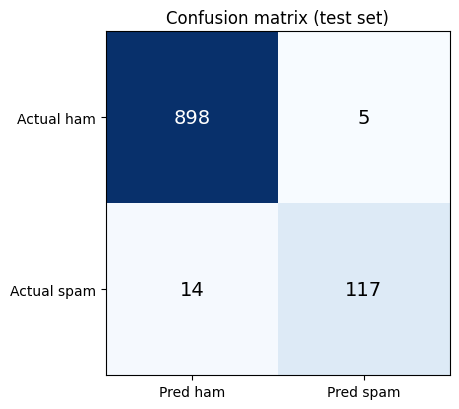

In [4]:
class MultinomialNBScratch:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.log_prior_ = np.log(np.array([(y == c).mean() for c in self.classes_]))
        counts = np.vstack([np.asarray(X[y == c].sum(axis=0)).ravel() for c in self.classes_]).astype(float)
        self.counts_ = counts
        V = counts.shape[1]
        with np.errstate(divide="ignore"):                               # alpha = 0 gives log(0) = -inf (demo below)
            self.log_lik_ = np.log((counts + self.alpha) / (counts.sum(axis=1, keepdims=True) + self.alpha * V))
        return self

    def joint_log(self, X):
        return X @ self.log_lik_.T + self.log_prior_                      # log P(class) + sum of log P(word|class)

    def predict(self, X):
        return self.classes_[np.argmax(self.joint_log(X), axis=1)]

    def predict_proba(self, X):
        J = self.joint_log(X)
        J = J - J.max(axis=1, keepdims=True)                              # stable softmax
        P = np.exp(J)
        return P / P.sum(axis=1, keepdims=True)

def cls_metrics(y, p):
    tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum())
    fn = int(((p == 0) & (y == 1)).sum()); tn = int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"Accuracy": (tp + tn) / len(y), "Precision": prec, "Recall": rec, "F1": f1, "TP": tp, "FP": fp, "FN": fn, "TN": tn}

nb = MultinomialNBScratch(alpha=1.0).fit(Xtr, ytr)
pred = nb.predict(Xte)
m = cls_metrics(yte, pred)
print(pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in m.items()}).to_string())
print("\nBaseline accuracy (always ham):", round(1 - yte.mean(), 4))

cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
plt.figure(figsize=(4.8, 4.2))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks([0, 1], ["Pred ham", "Pred spam"]); plt.yticks([0, 1], ["Actual ham", "Actual spam"])
plt.title("Confusion matrix (test set)"); plt.tight_layout(); plt.show()

**Reading the result**
- Accuracy alone is misleading here: always predicting `ham` already scores about 87%. So we also look at **precision** (of messages flagged spam, how many really are) and **recall** (of all spam, how much we caught)
- A **false positive** (real message sent to the spam folder) is usually worse than a **false negative** (one spam slips through)

In [5]:
# Cross-check with scikit-learn's MultinomialNB
from sklearn.naive_bayes import MultinomialNB

sk = MultinomialNB(alpha=1.0).fit(Xtr, ytr)
print("Same predictions as scikit-learn :", bool((sk.predict(Xte) == pred).all()))
print("Same probabilities (atol 1e-6)   :", bool(np.allclose(sk.predict_proba(Xte), nb.predict_proba(Xte), atol=1e-6)))

Same predictions as scikit-learn : True
Same probabilities (atol 1e-6)   : True


# Part B — Why Laplace Smoothing Matters
We vary the smoothing parameter α. With **α = 0** a word that never appeared in one class gets probability 0 there, which zeroes the entire product.

 alpha  Accuracy  Precision  Recall     F1  msgs with a class score = -inf  msgs with BOTH = -inf
  0.00    0.9400     0.8966  0.5954 0.7156                             942                     80
  0.01    0.9787     0.9291  0.9008 0.9147                               0                      0
  0.10    0.9816     0.9242  0.9313 0.9278                               0                      0
  0.50    0.9865     0.9466  0.9466 0.9466                               0                      0
  1.00    0.9816     0.9590  0.8931 0.9249                               0                      0
  2.00    0.9797     0.9661  0.8702 0.9157                               0                      0
  5.00    0.9671     1.0000  0.7405 0.8509                               0                      0
 10.00    0.9536     1.0000  0.6336 0.7757                               0                      0


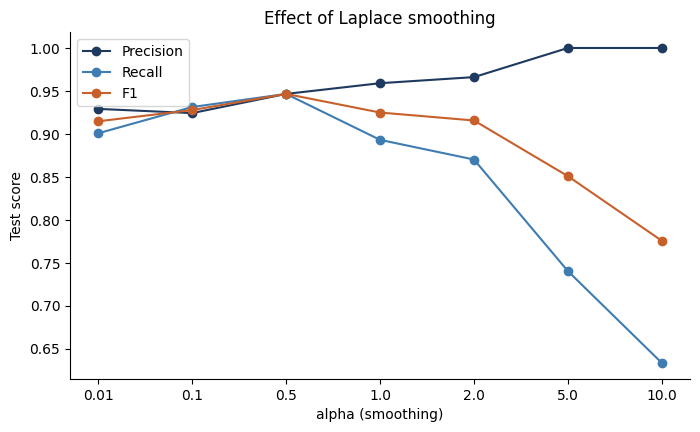

In [6]:
rows = []
for a in [0, 0.01, 0.1, 0.5, 1, 2, 5, 10]:
    model = MultinomialNBScratch(alpha=a).fit(Xtr, ytr)
    J = model.joint_log(Xte)
    mm = cls_metrics(yte, model.predict(Xte))
    rows.append({"alpha": a, "Accuracy": mm["Accuracy"], "Precision": mm["Precision"], "Recall": mm["Recall"], "F1": mm["F1"],
                 "msgs with a class score = -inf": int(np.isinf(J).any(axis=1).sum()),
                 "msgs with BOTH = -inf": int(np.isinf(J).all(axis=1).sum())})
sweep = pd.DataFrame(rows)
print(sweep.round(4).to_string(index=False))

s = sweep[sweep.alpha > 0]
plt.figure(figsize=(8, 4.5))
for col, c in [("Precision", navy), ("Recall", blue), ("F1", accent)]:
    plt.plot(s.alpha.astype(str), s[col], marker="o", color=c, label=col)
plt.xlabel("alpha (smoothing)"); plt.ylabel("Test score"); plt.title("Effect of Laplace smoothing"); plt.legend()
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

**What to notice**
- With α = 0, most test messages contain at least one word never seen in a class, so that class gets score −∞ (probability 0). Messages where *both* classes are −∞ cannot be decided and default to `ham`. Spam recall collapses
- As α grows, precision rises but recall falls (everything is smoothed towards uniform). On this split α = 0.5 gave the best F1, but choosing α by looking at the test set is optimistic; in practice α is tuned on a validation split or by cross-validation. We keep α = 1, the standard default

# Part C — What Did the Model Learn?
Words with the largest ratio log P(w|spam) − log P(w|ham) push a message towards spam; the most negative push it towards ham. We only keep words seen at least 5 times, so rare words do not dominate.

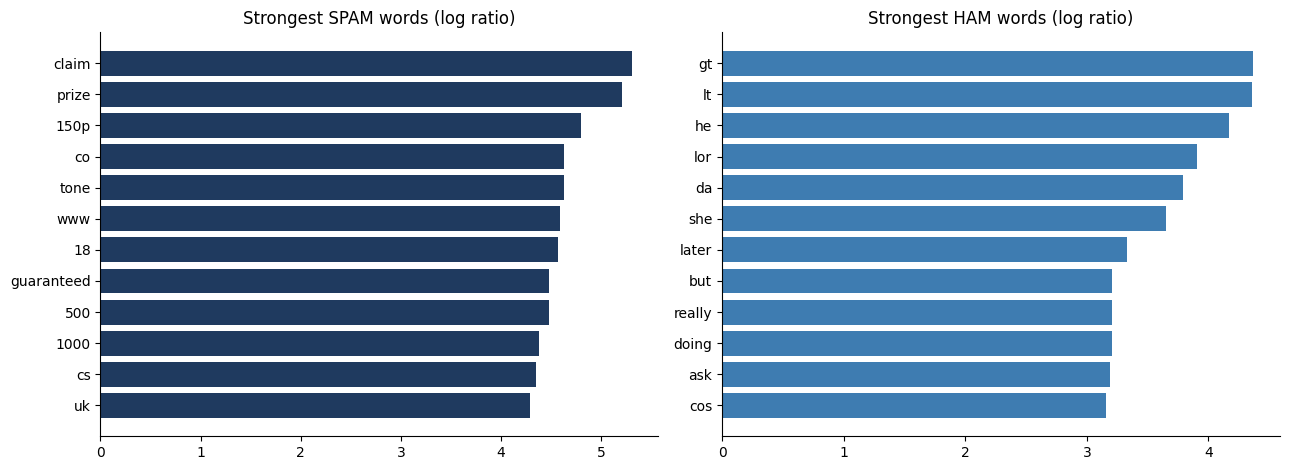

Top spam words: claim, prize, 150p, co, tone, www, 18, guaranteed, 500, 1000, cs, uk
Top ham words : gt, lt, he, lor, da, she, later, but, really, doing, ask, cos


In [7]:
ratio = nb.log_lik_[1] - nb.log_lik_[0]
common = (nb.counts_.sum(axis=0) >= 5)
idx = np.where(common)[0]
order = idx[np.argsort(ratio[idx])]
top_ham, top_spam = order[:12], order[::-1][:12]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].barh(terms[top_spam][::-1], ratio[top_spam][::-1], color=navy)
ax[0].set_title("Strongest SPAM words (log ratio)")
ax[1].barh(terms[top_ham][::-1], -ratio[top_ham][::-1], color=blue)
ax[1].set_title("Strongest HAM words (log ratio)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("Top spam words:", ", ".join(terms[top_spam]))
print("Top ham words :", ", ".join(terms[top_ham]))

# Part D — Confidence and Stability
Naive Bayes multiplies many "independent" pieces of evidence, even when they are correlated. That tends to make its probabilities **too extreme** (close to 0 or 1). We check that, and then repeat the experiment on 10 random splits to see how stable the result is.

Share of test messages with P(spam) < 0.01 or > 0.99 : 91.7%
Wrong predictions made with >99% confidence          : 6 of 19


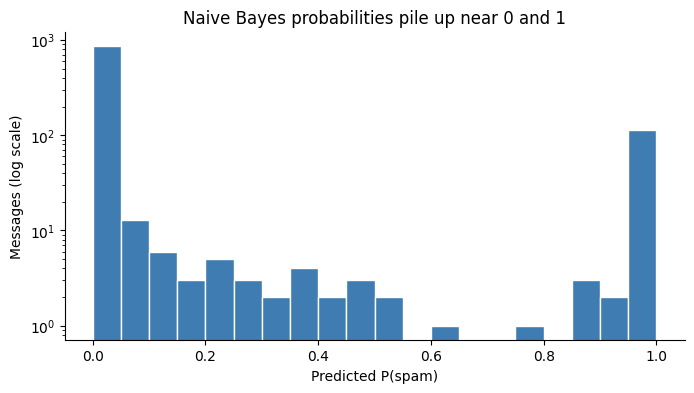


10 random splits (mean / std):
             Mean     Std
Accuracy   0.9855  0.0039
Precision  0.9678  0.0125
Recall     0.9160  0.0262
F1         0.9410  0.0164


In [8]:
p_spam = nb.predict_proba(Xte)[:, 1]
extreme = ((p_spam < 0.01) | (p_spam > 0.99)).mean()
wrong = pred != yte
print(f"Share of test messages with P(spam) < 0.01 or > 0.99 : {extreme:.1%}")
print(f"Wrong predictions made with >99% confidence          : {int((wrong & ((p_spam < 0.01) | (p_spam > 0.99))).sum())} of {int(wrong.sum())}")

plt.figure(figsize=(8, 4))
plt.hist(p_spam, bins=20, color=blue, edgecolor="white")
plt.yscale("log"); plt.xlabel("Predicted P(spam)"); plt.ylabel("Messages (log scale)")
plt.title("Naive Bayes probabilities pile up near 0 and 1"); plt.gca().spines[["top", "right"]].set_visible(False)
plt.show()

rows = []
for seed in range(10):
    a, b, ya, yb = train_test_split(df.message, df.y.values, test_size=0.2, stratify=df.y.values, random_state=seed)
    v = CountVectorizer(lowercase=True); Xa = v.fit_transform(a); Xb = v.transform(b)
    mm = cls_metrics(yb, MultinomialNBScratch(1.0).fit(Xa, ya).predict(Xb))
    rows.append({k: mm[k] for k in ["Accuracy", "Precision", "Recall", "F1"]})
rob = pd.DataFrame(rows)
print("\n10 random splits (mean / std):")
print(pd.DataFrame({"Mean": rob.mean(), "Std": rob.std()}).round(4).to_string())

## Final Conclusion
- **Result (α = 1, one split):** accuracy 0.982, precision 0.959, recall 0.893, F1 0.925, compared with 0.873 accuracy for "always ham". Over 10 random splits: accuracy 0.986 ± 0.004, precision 0.968, recall 0.916 ± 0.026, F1 0.941 ± 0.016.
- **Precision beats recall:** the filter rarely sends a real message to spam (5 false positives on the test set) but misses about 1 in 10 spam messages (14 false negatives).
- **Smoothing is essential:** with α = 0 the F1 drops to 0.716 and spam recall to 0.595, because most messages contain a word unseen in one class.
- **What it learned:** strongest spam words include claim, prize, guaranteed, www, 150p; strongest ham words are chatty ones like lor, da, later, cos.
- **Overconfident probabilities:** 91.7% of test messages get P(spam) below 0.01 or above 0.99, and 6 of the 19 mistakes were made with more than 99% confidence. Use the ranking, not the raw probability.
- **Validation:** our scratch model matches scikit-learn's MultinomialNB exactly (same predictions, same probabilities).


## Viva Questions
| Question | Short answer |
|---|---|
| State Bayes theorem | P(A\|B) = P(B\|A) · P(A) / P(B): update a prior belief with the likelihood of the evidence |
| Why is it called "naive"? | It assumes all features are independent given the class, which is rarely exactly true |
| Why does it still work well? | It only needs the *ranking* of class scores to be right, not exact probabilities; it also has few parameters, so it needs little data |
| What is the zero-frequency problem? | A word unseen in a class gives probability 0 and kills the whole product |
| What is Laplace smoothing? | Add α (usually 1) to every word count so no probability is ever 0 |
| Why use log probabilities? | Products of many small numbers underflow; sums of logs are stable and keep the same winner |
| Why can we ignore P(message)? | It is the same for every class, so it does not change which class scores highest |
| Multinomial vs Bernoulli vs Gaussian? | Word counts / word present-absent / continuous numbers with a bell curve per class |
| Why is accuracy not enough here? | Only ~13% of messages are spam, so "always ham" already scores ~87%; use precision, recall and F1 |
| Which error is worse for a spam filter? | A false positive (real message lost), so precision matters a lot |
| Weaknesses of Naive Bayes? | Independence assumption, overconfident probabilities, depends on the training vocabulary |
| Strengths? | Very fast, simple, works with small data and many features, easy to interpret |